# Machine Learning Assignment — Task 1: Tabular Data
## Rain prediction on the Australian weather dataset (weatherAUS)

**Course:** Machine Learning (_<course code>_) · Semester I, 2026–2027 · Faculty of Computer Science and Engineering, HCMUT – VNU-HCM
**Instructor:** _<instructor name>_
**Group:** _<group name>_ — _<member 1 (ID)>_, _<member 2 (ID)>_, _<member 3 (ID)>_
**GitHub:** _<repository link>_ · **Report:** `reports/report.pdf`

**Goal.** Predict whether it will rain tomorrow (`RainTomorrow`) from today's weather observations at 49 Australian stations, using a **configurable traditional ML pipeline**
(EDA → cleaning → imputation → encoding → scaling → PCA → model → evaluation) and compare it with one **deep learning pipeline (MLP with categorical embeddings)**.

| Model | Scaler | PCA | Encoding |
|---|---|---|---|
| Logistic Regression | StandardScaler | none | one-hot |
| RBF-kernel SVM | quantile clipping + MinMax(0,1) | 95% variance | one-hot |
| CatBoost (gradient boosting) | none | none | native categorical |
| MLP (deep learning) | quantile → normal | none | learned embeddings |

These are the *hypotheses*; Experiment 1 tests the scaler / PCA choice against alternatives, Experiment 2 tests the other preprocessing steps.

> **How to run:** `Runtime → Run all`. Data is downloaded from a public GitHub link; nothing is mounted. A full run takes about 35 minutes on Colab CPU.
> Set `FAST_MODE = True` below for a ~7-minute smoke run on subsampled data (numbers will then differ from the report).

## 0. Setup

In [1]:
FAST_MODE = False   # True -> quick smoke run (subsampled training, fewer epochs / tuning combos)
REPO_URL = "https://github.com/Reiko0908/aus-rain-ml.git"  # <- set after pushing the repo

import os, sys, subprocess, importlib.util
if os.path.isdir("modules"):            # running from the project root
    ROOT = os.getcwd()
elif os.path.isdir("../modules"):       # running from notebooks/
    ROOT = os.path.abspath("..")
else:                                    # fresh Colab runtime: clone the project
    subprocess.run(["git", "clone", "-q", REPO_URL, "ml-task1-weather-aus"], check=True)
    ROOT = os.path.abspath("ml-task1-weather-aus")
os.chdir(ROOT)
sys.path.insert(0, ROOT)

for pkg in ["catboost", "h5py"]:        # torch, sklearn, pandas are preinstalled on Colab
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
print("project root:", ROOT)

project root: /home/claude/ml-task1


In [2]:
import random, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, sklearn, catboost
from IPython.display import display

from modules import data_loader as dl, eda, configs
from modules.preprocessing import build_preprocessor, make_config
from modules.experiment import run_grid, run_experiment, tune, save_features, save_npy
from modules.evaluation import (compute_metrics, plot_confusion_matrices, plot_roc_curves,
                                plot_ablation, plot_learning_curve, plot_importances)
from modules.tabular_mlp import MLPClassifier
from modules import plot_style; plot_style.apply()

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
FIG, RES, FEAT = "reports/figures", "reports/results", "features"
for d in (FIG, RES, FEAT): os.makedirs(d, exist_ok=True)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)

SUB = 15_000 if FAST_MODE else None                     # training subsample for every model in FAST_MODE
SVM_SUB = 6_000 if FAST_MODE else configs.SVM_SUBSAMPLE
print(f"FAST_MODE={FAST_MODE} | sklearn {sklearn.__version__} | catboost {catboost.__version__} | "
      f"torch {torch.__version__} | device: {'cuda' if torch.cuda.is_available() else 'cpu'}")

FAST_MODE=False | sklearn 1.9.1 | catboost 1.2.10 | torch 2.14.1+cu130 | device: cpu


## 1. Data acquisition
**Rain in Australia (`weatherAUS`)**: 145,460 daily observations from 49 weather stations (1 Nov 2007 – 25 Jun 2017), 22 measured columns + the label `RainTomorrow`.
The observations are published by the Australian Bureau of Meteorology and packaged in the R package `rattle` (Williams) and on Kaggle (<https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package>).
The file is downloaded from a public GitHub mirror of that CSV; nothing is changed at load time.

In [3]:
print("source:", dl.DATA_URL)
raw = dl.load_raw("data")
print("shape:", raw.shape)
raw.head()

source: https://raw.githubusercontent.com/acakin/weatherAUS/master/weatherAUS.csv


shape: (145460, 23)


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,WNW,20.0,24.0,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,WSW,4.0,22.0,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,WSW,19.0,26.0,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,E,11.0,9.0,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,NW,7.0,20.0,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


## 2. Exploratory Data Analysis
### 2.1 Column overview: types, cardinality, missing values

In [4]:
ov = eda.overview(raw); ov.to_csv(f"{RES}/eda_overview.csv"); ov

,dtype,n_unique,n_missing,pct_missing,example
Date,str,3436,0,0.00,"2008-12-01, 2008-12-02, 2008-12-03"
Location,str,49,0,0.00,"Albury, BadgerysCreek, Cobar"
MinTemp,float64,389,1485,1.02,"13.4, 7.4, 12.9"
MaxTemp,float64,505,1261,0.87,"22.9, 25.1, 25.7"
Rainfall,float64,681,3261,2.24,"0.6, 0.0, 1.0"
Evaporation,float64,358,62790,43.17,"12.0, 14.8, 12.6"
Sunshine,float64,145,69835,48.01,"12.3, 13.0, 13.3"
WindGustDir,str,16,10326,7.10,"W, WNW, WSW"
WindGustSpeed,float64,67,10263,7.06,"44.0, 46.0, 24.0"
WindDir9am,str,16,10566,7.26,"W, NNW, SE"


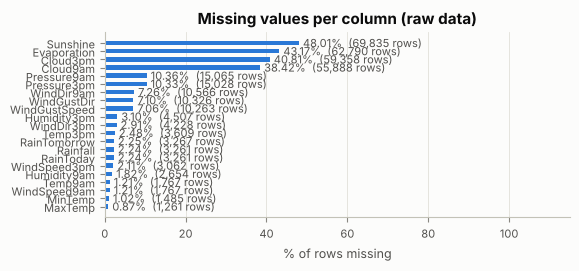

,n_missing,pct_missing,rain | missing,rain | present
Sunshine,67816.0,47.7,0.222,0.226
Evaporation,60843.0,42.8,0.230,0.220
Cloud3pm,57094.0,40.2,0.203,0.238
Cloud9am,53657.0,37.7,0.210,0.233
Pressure9am,14014.0,9.9,0.221,0.224
WindGustDir,9330.0,6.6,0.264,0.221


,pct_missing,stations that never record it,share of the gaps from those stations
Evaporation,43.2,16 of 49,0.725
Sunshine,48.0,19 of 49,0.761
WindGustDir,7.1,2 of 49,0.589
WindGustSpeed,7.1,2 of 49,0.592
WindDir9am,7.3,0 of 49,0.0
Pressure9am,10.4,4 of 49,0.804
Pressure3pm,10.3,4 of 49,0.806
Cloud9am,38.4,12 of 49,0.626
Cloud3pm,40.8,12 of 49,0.589


In [5]:
eda.plot_missing(raw, FIG); plt.show()
display(eda.missingness_check(raw)); display(eda.station_missing(raw))

**Missing values.** There are **343,248 missing cells**, and **61.2% of the rows have at least one gap** — numeric *and* categorical columns are affected:
`Sunshine` (48.0%), `Evaporation` (43.2%), `Cloud3pm` (40.8%), `Cloud9am` (38.4%), `Pressure9am/3pm` (10%), `WindGustDir/Speed` and `WindDir9am` (7%), plus a few percent in the others.
Most of the gaps are **structural**: whole stations do not measure some quantity — 19 of the 49 stations never record `Sunshine` (they cause 76% of its gaps), 16 never record `Evaporation` (73%), 12 never record `Cloud` (≈ 60%).
The *fact* that a value is missing says little about tomorrow's weather (e.g. 22.2% rain when `Sunshine` is missing vs. 22.6% when present; 20.3% vs. 23.8% for `Cloud3pm`), so — unlike a column where "missing" is informative — **the value used to fill the gap matters**.
That makes this dataset a real test of the imputers: median, mean, KNN and iterative (regression-based) imputation are compared in Experiment 2, and categorical gaps get an explicit "Missing" category or the most frequent one.

### 2.2 Target, duplicates and data cleaning

exact duplicate rows: 0
columns: ['Date', 'Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RainToday', 'RainTomorrow'] (no RISK_MM)
rainy-tomorrow share (raw, labelled rows): 0.2242


 - exact duplicate rows removed: 0
 - rows with unknown RainTomorrow removed (no label to learn from): 3,267
 => 142,193 rows remain (from 145,460), 2007-11-01 to 2017-06-25
rainy-tomorrow share (clean): 0.2242


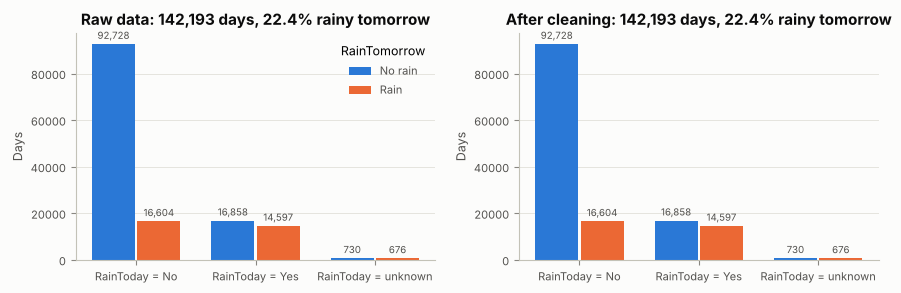

In [6]:
print("exact duplicate rows:", raw.duplicated().sum())
print("columns:", list(raw.columns), "(no RISK_MM)")
print("rainy-tomorrow share (raw, labelled rows):", round((raw.RainTomorrow == "Yes").sum() / raw.RainTomorrow.notna().sum(), 4))
df_dated = dl.clean(raw)                      # keeps Date (sorted by date)
df = dl.engineer_features(df_dated)
print("rainy-tomorrow share (clean):", round(df[dl.TARGET].mean(), 4))
eda.plot_target(raw, df_dated, FIG); plt.show()

- There are **no duplicate rows**. **3,267 rows (2.2%) have no `RainTomorrow` label** and are removed: there is nothing to learn from or to evaluate on. `RainToday` is missing for 1,406 rows (exactly those without a `Rainfall` value) and becomes a "Missing" category.
- **No leakage column.** Every feature is measured *today*; the label is tomorrow's rain. (Older copies of this dataset contain `RISK_MM`, tomorrow's rainfall amount, which is the label in disguise; this file does not have it.)
  `Date` is replaced by the month number (seasonality); the calendar year and the exact date are not used, because a model must work for future days.
- After cleaning: **142,193 days, 22.4% followed by rain** → imbalanced (about 3.5 : 1), so accuracy alone is misleading (always answering "no rain" already gives 77.6%).
  We therefore report **macro-F1** (primary), F1 of the "rain" class, ROC-AUC, precision, recall and accuracy.
- **Chronological split.** Consecutive days at one station are strongly correlated, and the label of day *t* is exactly the feature `RainToday` of day *t + 1*. With a random split, the neighbours of a test day sit in the training set, which flatters the scores. We therefore train on the oldest 70% of the days (to Jan 2015), select models on the next 15% (to Apr 2016) and report the newest 15% (to Jun 2017). The rain rate drifts a little between the parts (22.6% / 20.4% / 23.8%). Section 3 measures how much a random split would have inflated the scores.

### 2.3 Numeric features: statistics, distributions, outliers

In [7]:
ns = eda.numeric_summary(df); ns.to_csv(f"{RES}/eda_numeric_summary.csv"); ns

,count,mean,std,min,25%,50%,75%,max,skew
MinTemp,141556.0,12.19,6.40,-8.5,7.6,12.0,16.8,33.9,0.02
MaxTemp,141871.0,23.23,7.12,-4.8,17.9,22.6,28.2,48.1,0.22
Rainfall,140787.0,2.35,8.47,0.0,0.0,0.0,0.8,371.0,9.89
Evaporation,81350.0,5.47,4.19,0.0,2.6,4.8,7.4,145.0,3.75
Sunshine,74377.0,7.62,3.78,0.0,4.9,8.5,10.6,14.5,-0.50
WindGustSpeed,132923.0,39.98,13.59,6.0,31.0,39.0,48.0,135.0,0.87
WindSpeed9am,140845.0,14.00,8.89,0.0,7.0,13.0,19.0,130.0,0.78
WindSpeed3pm,139563.0,18.64,8.80,0.0,13.0,19.0,24.0,87.0,0.63
Humidity9am,140419.0,68.84,19.05,0.0,57.0,70.0,83.0,100.0,-0.48
Humidity3pm,138583.0,51.48,20.80,0.0,37.0,52.0,66.0,100.0,0.03


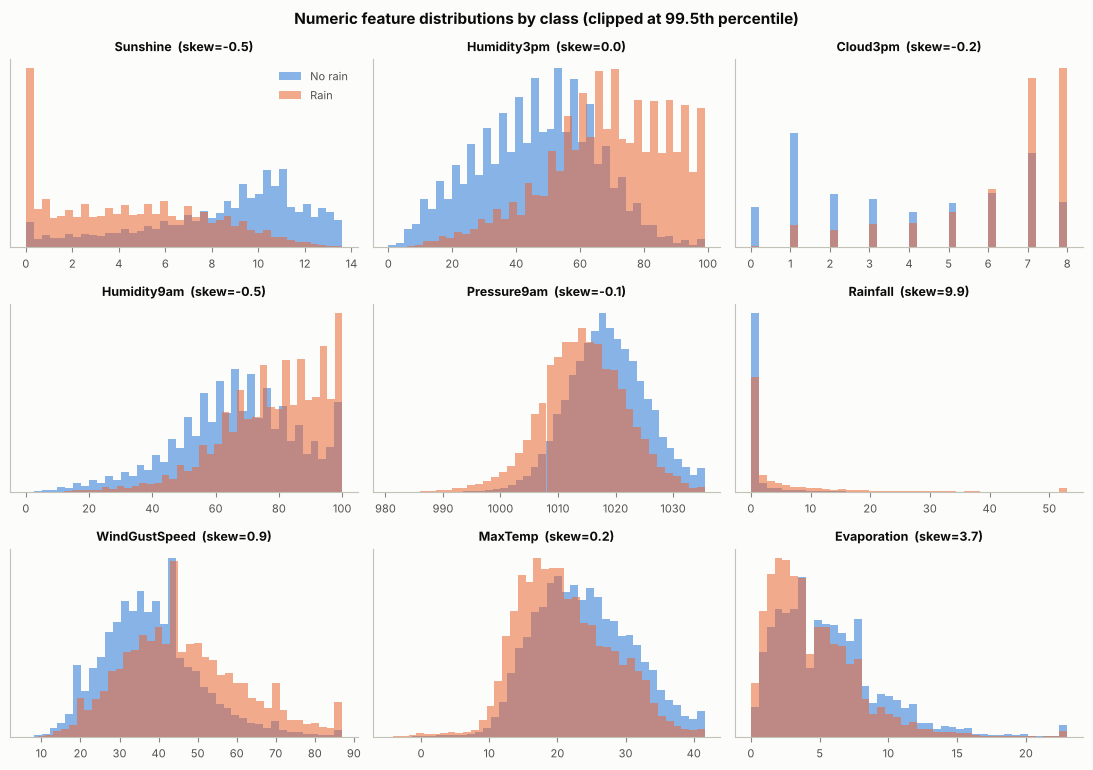

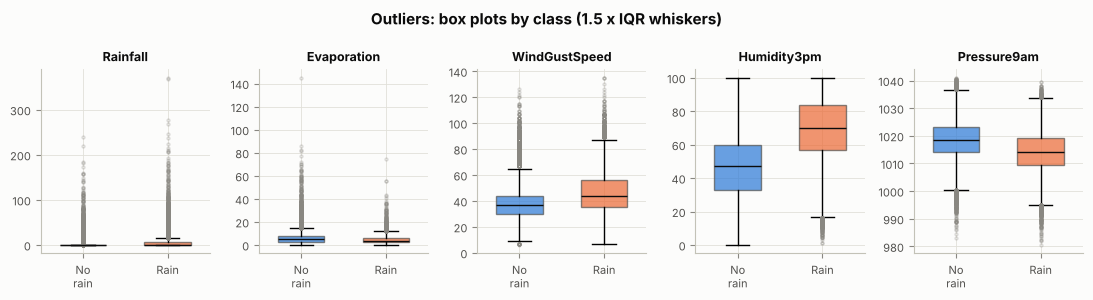

In [8]:
eda.plot_numeric_distributions(df, ["Sunshine", "Humidity3pm", "Cloud3pm", "Humidity9am", "Pressure9am",
                                    "Rainfall", "WindGustSpeed", "MaxTemp", "Evaporation"], FIG)
plt.show()
eda.plot_boxplots(df, ["Rainfall", "Evaporation", "WindGustSpeed", "Humidity3pm", "Pressure9am"], FIG); plt.show()

In [9]:
out = eda.iqr_outliers(df); out.to_csv(f"{RES}/eda_iqr_outliers.csv"); out

,Q1,Q3,IQR,lower,upper,n_outliers,pct_outliers,max
Rainfall,0.0,0.8,0.8,-1.20,2.00,25228,17.74,371.0
WindGustSpeed,31.0,48.0,17.0,5.50,73.50,3006,2.11,135.0
WindSpeed3pm,13.0,24.0,11.0,-3.50,40.50,2458,1.73,87.0
Evaporation,2.6,7.4,4.8,-4.60,14.60,1954,1.37,145.0
WindSpeed9am,7.0,19.0,12.0,-11.00,37.00,1739,1.22,130.0
Humidity9am,57.0,83.0,26.0,18.00,122.00,1419,1.00,100.0
Pressure9am,1012.9,1022.4,9.5,998.65,1036.65,1174,0.83,1041.0
Pressure3pm,1010.4,1020.0,9.6,996.00,1034.40,906,0.64,1039.6
Temp3pm,16.6,26.4,9.8,1.90,41.10,735,0.52,46.7
MaxTemp,17.9,28.2,10.3,2.45,43.65,459,0.32,48.1


- The strongest numeric signals are `Sunshine` (r = −0.45), `Humidity3pm` (+0.45), `Cloud3pm` (+0.38), `Cloud9am` (+0.32), `Humidity9am` (+0.26), `Pressure9am` (−0.25), `Rainfall` (+0.24) and `WindGustSpeed` (+0.23).
- `Rainfall` (skew 9.9) and `Evaporation` (skew 3.8) are right-skewed: 63.5% of the days have no rain at all and the maximum is 371 mm. These two columns are the ones `log1p` is applied to when `log_skewed=True`.
- **Outliers.** The 1.5×IQR rule flags 17.7% of `Rainfall` (every day with more than 2 mm) and 1–2% of the wind, evaporation and humidity columns. These are real weather events (storms, gales), not entry errors, so they are *not* removed; the `OutlierClipper` offers `iqr` and `quantile` (1st–99th percentile) winsorisation for models that are sensitive to them (RBF-SVM with MinMax scaling), and Experiment 1–2 measure whether it helps. For zero-IQR columns `iqr` mode would clip every non-zero value, so the clipper skips them.
- **Heavy redundancy.** `MaxTemp`–`Temp3pm` (|r| = 0.98), `Pressure9am`–`Pressure3pm` (0.96), `MinTemp`–`Temp9am` (0.90), `MaxTemp`–`Temp9am` (0.89), `Temp9am`–`Temp3pm` (0.86) and `Sunshine`–`Cloud3pm` (0.70) all measure nearly the same thing. This is exactly what PCA compresses, so this dataset is a fair test of the PCA step.

### 2.4 Categorical features vs. rain tomorrow

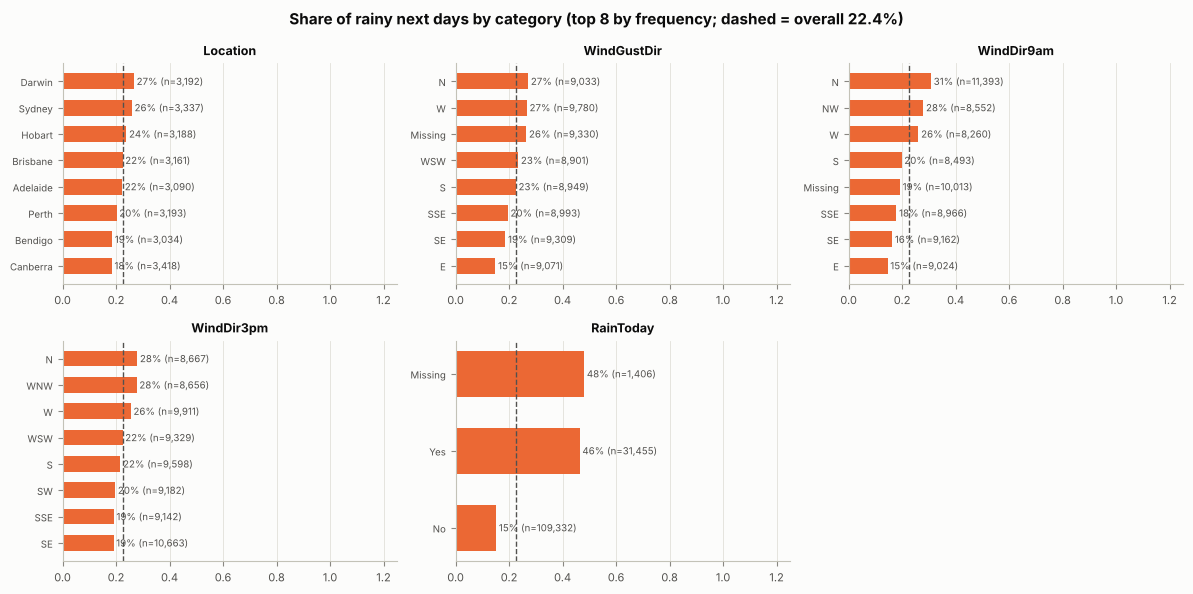

             Location  WindGustDir  WindDir9am  WindDir3pm  RainToday
cardinality        49           16          16          16          2


In [10]:
eda.plot_categorical_rates(df, dl.CAT_COLS, FIG, top=8); plt.show()
print(df[dl.CAT_COLS].nunique().rename("cardinality").to_frame().T)

- `RainToday` is a strong signal: 46.4% of days after a rainy day are followed by rain vs. 15.2% after a dry day. Stations differ widely: from 6.8% (Woomera) and 7.6% (Uluru) in the desert to 33.7% (Walpole) and 36.5% (Portland) on the wet south coast. Wind from the north-west (NW 28.5%, NNW 28.4% of days) brings rain far more often than wind from the east (E 14.9%, ENE 16.1%).
- Cardinality: `Location` 49 levels, the three wind-direction columns 16 each, `RainToday` 2 (+ "Missing"). One-hot encoding therefore widens the matrix from 22 to **120 columns**; levels with fewer than 30 training occurrences are merged into one "infrequent" column (`onehot_min_frequency`), and ordinal and (cross-fitted) target encoding are compared in Experiment 2.
- The 16 compass directions are a cyclic variable; one-hot encoding ignores that N and NNE are neighbours. We keep them categorical because the assignment is about encoding categorical data.

### 2.5 Season, humidity and correlations

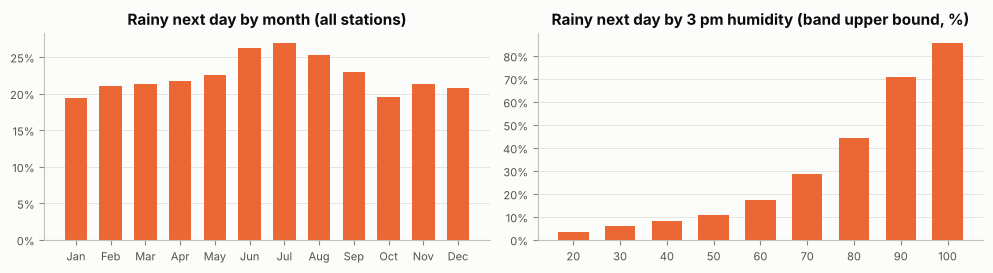

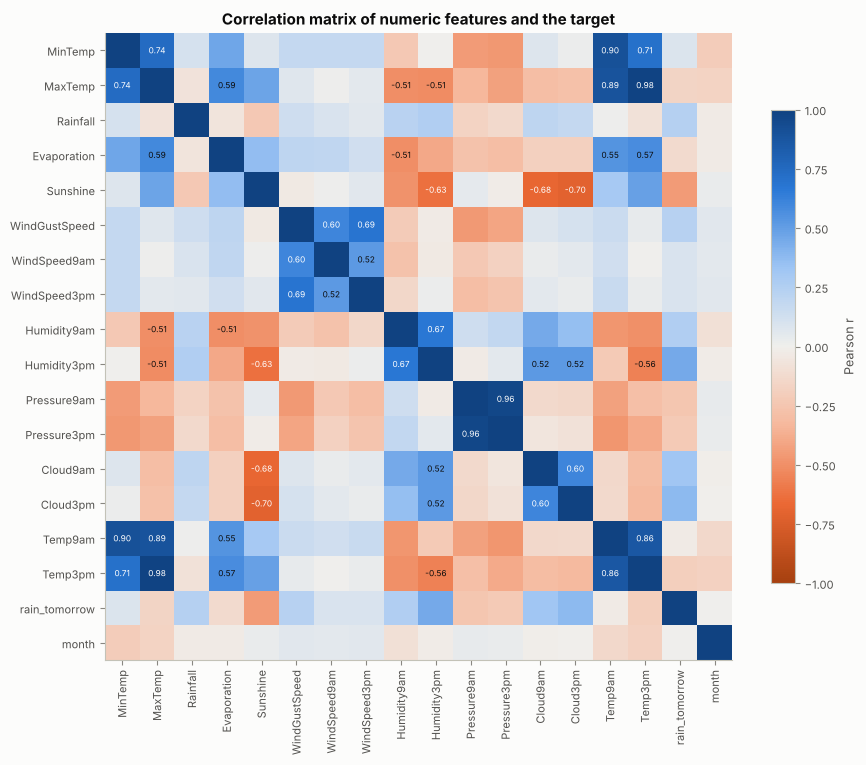

,Sunshine,Humidity3pm,Cloud3pm,Cloud9am,Humidity9am,Pressure9am,Rainfall,WindGustSpeed,Pressure3pm,Temp3pm,MaxTemp,Evaporation,WindSpeed9am,WindSpeed3pm,MinTemp,Temp9am,month
corr_with_rain_tomorrow,-0.451,0.446,0.382,0.317,0.257,-0.246,0.239,0.234,-0.226,-0.192,-0.159,-0.119,0.091,0.088,0.084,-0.026,0.007


In [11]:
eda.plot_profiles(df, FIG); plt.show()
eda.plot_correlation(df, FIG); plt.show()
eda.target_correlations(df).to_frame("corr_with_rain_tomorrow").T

- Rain follows a seasonal cycle: 26–27% of the days in June–August are followed by rain vs. 19–21% in January–March, so `month` is a useful feature.
- 3 pm humidity is the strongest single predictor and acts in a clearly **non-linear** way: 3.6% of days are followed by rain when humidity is ≤ 20%, 17% at 50–60%, and 86% above 90%. This is the kind of structure a linear model can only approximate.

## 3. Preprocessing pipeline
**Chronological 70 / 15 / 15** split (oldest days train, newest days test). **Validation** is used for every comparison and model selection; **test** is touched only once, in Section 7.

Each experiment is a config dict → `build_pipeline(cfg)` assembles an sklearn `Pipeline`, so every statistic (medians, category lists, scaler ranges, PCA axes) is fitted on the training split only:

```
ColumnTransformer
 ├─ numeric : imputer {median|mean|knn|iterative} → [log1p skewed] → [outlier clip {iqr|quantile}]
 └─ categorical : imputer {constant "Missing"|most_frequent} → encoder {onehot|ordinal|target}
→ scaler {standard | minmax(feature_range) | robust | none}
→ PCA {none | 0.90 | 0.95 variance}
→ model {LR | RBF-SVM | CatBoost | CatBoost-native}
```

In [12]:
X_train, X_val, X_test, y_train, y_val, y_test = dl.split(*dl.get_xy(df), seed=SEED)
print(f"train {X_train.shape}  val {X_val.shape}  test {X_test.shape}")
print("rainy share (train / val / test):", [round(v.mean(), 4) for v in (y_train, y_val, y_test)])
print("numeric:", dl.NUM_COLS); print("categorical:", dl.CAT_COLS)
example = make_config(scaler="minmax", feature_range=(0, 1), pca=0.95, outliers="quantile")
pipe = build_preprocessor(example).fit(X_train, y_train)
print("encoded width:", len(pipe.named_steps["columns"].get_feature_names_out()),
      "-> after PCA 95%:", pipe.named_steps["reduce"].n_components_)
print(pipe)

train (99535, 22)  val (21329, 22)  test (21329, 22)
rainy share (train / val / test): [np.float64(0.2256), np.float64(0.2041), np.float64(0.2376)]
numeric: ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'month']
categorical: ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday']


encoded width: 120 -> after PCA 95%: 92
Pipeline(steps=[('columns',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('clip',
                                                                   OutlierClipper(method='quantile'))]),
                                                  ['MinTemp', 'MaxTemp',
                                                   'Rainfall', 'Evaporation',
                                                   'Sunshine', 'WindGustSpeed',
                                                   'WindSpeed9am',
                                                   'WindSpeed3pm',
                                                   'Humidity9am', 'Humidity3pm',
                                                   'Pressure9am', 'Pre

### 3.1 How much would a random split inflate the scores?
The same two fast models (LR, CatBoost with one-hot encoding) are trained on a **random stratified 70%** of the data and on the **chronological 70%**, and both are evaluated on a 15% validation part of their own split.

In [13]:
from sklearn.model_selection import train_test_split
Xa, ya = dl.get_xy(df)
Xr_tv, Xr_te, yr_tv, yr_te = train_test_split(Xa, ya, test_size=0.15, stratify=ya, random_state=SEED)
Xr_tr, Xr_va, yr_tr, yr_va = train_test_split(Xr_tv, yr_tv, test_size=0.15 / 0.85, stratify=yr_tv, random_state=SEED)
quick = [{"name": "LR", "model": "lr", "scaler": "standard"},
         {"name": "CatBoost (one-hot)", "model": "catboost", "scaler": "none"}]
rows = []
for split_name, (a, b, c, d) in {"random split": (Xr_tr, Xr_va, yr_tr, yr_va),
                                 "chronological split": (X_train, X_val, y_train, y_val)}.items():
    r = run_grid(quick, a, c, b, d, verbose=False)
    rows.append(r.assign(split=split_name))
split_check = pd.concat(rows)[["split", "name", "accuracy", "f1_macro", "roc_auc"]].reset_index(drop=True)
split_check.to_csv(f"{RES}/split_check.csv", index=False)
split_check

,split,name,accuracy,f1_macro,roc_auc
0,random split,LR,0.8468,0.7509,0.8718
1,random split,CatBoost (one-hot),0.8633,0.7805,0.8977
2,chronological split,LR,0.8543,0.7351,0.8679
3,chronological split,CatBoost (one-hot),0.8641,0.7560,0.8897


The random split gives **higher macro-F1** (LR +0.016, CatBoost +0.025) and **higher ROC-AUC** (+0.004, +0.008) than the chronological split: neighbouring days leak into the training data. Accuracy is not comparable between the rows because the rain share differs (22.4% vs. 20.4%). All following results use the chronological split.

## 4. Experiment 1 — scaler and PCA choice for each model (10 runs)
For each model, the recommended setting is compared with the few alternatives that matter. Everything else is fixed: median / "Missing" imputation, one-hot encoding (CatBoost-native: raw categories).
RBF-SVM is trained on a stratified 20k subsample (kernel SVM training scales ~O(n²)); LR and CatBoost use all 99.5k training rows.

In [14]:
exp1_cfgs = configs.scaler_pca_runs(SVM_SUB)
if SUB:
    for c in exp1_cfgs:
        if c["model"] != "svm": c["train_subsample"] = SUB
CFG = {c["name"]: c for c in exp1_cfgs}                # keep every config for later selection
exp1 = run_grid(exp1_cfgs, X_train, y_train, X_val, y_val, csv_path=f"{RES}/exp1_scaler_pca.csv")
exp1["family"] = exp1["name"].str.split(" | ", regex=False).str[0]
exp1.to_csv(f"{RES}/exp1_scaler_pca.csv", index=False)
exp1[["name", "n_features", "accuracy", "precision", "recall", "f1", "f1_macro", "roc_auc", "fit_s"]]

[ 1/10] LR | StandardScaler | no PCA (recommended) F1-macro=0.7351 AUC=0.8679 dims=120  fit=1.6s


[ 2/10] LR | MinMax(0,1) | no PCA                F1-macro=0.7344 AUC=0.8675 dims=120  fit=2.4s


[ 3/10] LR | StandardScaler | PCA 95%            F1-macro=0.6967 AUC=0.8440 dims=96   fit=3.9s


[ 4/10] RBF-SVM | clip + MinMax(0,1) | PCA 95% (recommended) F1-macro=0.7154 AUC=0.8541 dims=92   fit=17.1s


[ 5/10] RBF-SVM | MinMax(0,1) | PCA 95% (no clipping) F1-macro=0.7042 AUC=0.8499 dims=90   fit=16.8s


[ 6/10] RBF-SVM | clip + StandardScaler | PCA 95% F1-macro=0.7090 AUC=0.8552 dims=96   fit=13.6s


[ 7/10] RBF-SVM | clip + MinMax(0,1) | no PCA    F1-macro=0.7291 AUC=0.8693 dims=120  fit=15.9s


[ 8/10] CatBoost | native categoricals, no scaler, no PCA (recommended) F1-macro=0.7668 AUC=0.8941 dims=22   fit=41.7s


[ 9/10] CatBoost | one-hot, no scaler, no PCA    F1-macro=0.7560 AUC=0.8897 dims=120  fit=9.3s


[10/10] CatBoost | one-hot, StandardScaler, PCA 95% F1-macro=0.7192 AUC=0.8689 dims=96   fit=23.7s


,name,n_features,accuracy,precision,recall,f1,f1_macro,roc_auc,fit_s
0,LR | StandardScaler | no PCA (recommended),120,0.8543,0.7335,0.4495,0.5574,0.7351,0.8679,1.58
1,"LR | MinMax(0,1) | no PCA",120,0.8545,0.7373,0.4460,0.5558,0.7344,0.8675,2.43
2,LR | StandardScaler | PCA 95%,96,0.8403,0.7063,0.3728,0.4880,0.6967,0.8440,3.92
3,"RBF-SVM | clip + MinMax(0,1) | PCA 95% (recomm...",92,0.8503,0.7539,0.3962,0.5194,0.7154,0.8541,17.12
4,"RBF-SVM | MinMax(0,1) | PCA 95% (no clipping)",90,0.8458,0.7400,0.3771,0.4996,0.7042,0.8499,16.82
5,RBF-SVM | clip + StandardScaler | PCA 95%,96,0.8493,0.7628,0.3797,0.5070,0.7090,0.8552,13.58
6,"RBF-SVM | clip + MinMax(0,1) | no PCA",120,0.8570,0.7816,0.4159,0.5429,0.7291,0.8693,15.91
7,"CatBoost | native categoricals, no scaler, no ...",22,0.8683,0.7659,0.5110,0.6130,0.7668,0.8941,41.70
8,"CatBoost | one-hot, no scaler, no PCA",120,0.8641,0.7616,0.4864,0.5937,0.7560,0.8897,9.29
9,"CatBoost | one-hot, StandardScaler, PCA 95%",96,0.8494,0.7331,0.4125,0.5279,0.7192,0.8689,23.68


**What it shows** (validation macro-F1)
- **PCA 95% lowered macro-F1 for every model and compressed little.** LR 0.7351 → 0.6967, CatBoost (one-hot) 0.7560 → 0.7192, SVM 0.7291 → 0.7154, while the width only fell from 120 to 92–96 columns: the 103 one-hot columns are nearly orthogonal, so only the 17 numeric columns (temperatures, pressures) can be compressed.
- **Scaling matters for the SVM, not for LR or trees.** LR: StandardScaler 0.7351 vs. MinMax 0.7344. SVM after clipping: MinMax(0,1) 0.7154 beats StandardScaler 0.7090; quantile clipping adds +0.011 (0.7042 without it).
- **CatBoost:** native categorical handling beats one-hot (0.7668 vs. 0.7560, AUC 0.8941 vs. 0.8897) from 22 raw columns, but trains 4.5× slower (42 s vs. 9 s).
- **Ranking:** CatBoost is clearly ahead; LR is *not* behind the SVM. For the SVM the recommended pipeline with PCA 95% is slightly worse than the same pipeline without PCA (0.7154 vs. 0.7291); PCA 95% is kept as specified in the methodology and its cost is reported.

## 5. Experiment 2 — one-at-a-time ablations
Starting from the recommended configuration of LR and RBF-SVM, change **one** step at a time
(numeric imputation, categorical imputation, encoding, outlier handling, log-transform, class weighting) and measure the change in validation macro-F1.
KNN imputation is O(n²) and is only run for the SVM, whose training set is the 20k subsample.

[ 1/20] LR | baseline                            F1-macro=0.7351 AUC=0.8679 dims=120  fit=1.7s


[ 2/20] LR | cat_imputer=most_frequent           F1-macro=0.7351 AUC=0.8661 dims=116  fit=1.7s


[ 3/20] LR | num_imputer=mean                    F1-macro=0.7364 AUC=0.8679 dims=120  fit=1.5s


[ 4/20] LR | num_imputer=iterative               F1-macro=0.7481 AUC=0.8726 dims=120  fit=13.8s


[ 5/20] LR | encoder=ordinal                     F1-macro=0.7207 AUC=0.8579 dims=22   fit=0.6s


[ 6/20] LR | encoder=target                      F1-macro=0.7256 AUC=0.8629 dims=22   fit=0.6s


... (10 outputs left out)

[17/20] RBF-SVM | outliers=iqr                   F1-macro=0.7147 AUC=0.8523 dims=91   fit=19.5s


[18/20] RBF-SVM | log1p skewed                   F1-macro=0.7146 AUC=0.8542 dims=92   fit=17.8s


[19/20] RBF-SVM | class_weight=balanced          F1-macro=0.7425 AUC=0.8626 dims=92   fit=25.0s


[20/20] RBF-SVM | num_imputer=knn                F1-macro=0.7206 AUC=0.8505 dims=91   fit=38.0s


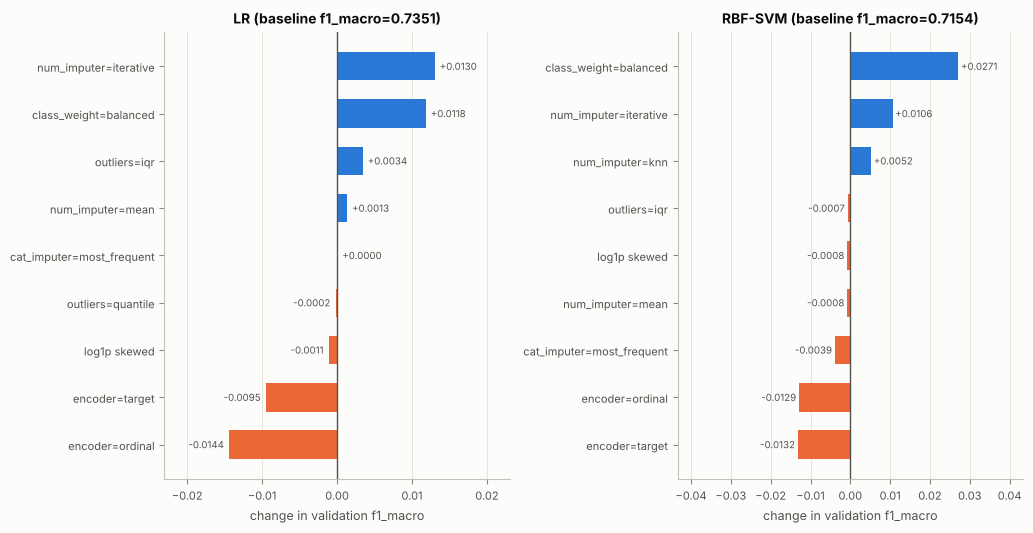

,name,n_features,precision,recall,f1,f1_macro,roc_auc,fit_s
0,LR | baseline,120,0.7335,0.4495,0.5574,0.7351,0.8679,1.66
1,LR | cat_imputer=most_frequent,116,0.7388,0.4469,0.5570,0.7351,0.8661,1.71
2,LR | num_imputer=mean,120,0.7340,0.4525,0.5598,0.7364,0.8679,1.47
3,LR | num_imputer=iterative,120,0.7252,0.4862,0.5822,0.7481,0.8726,13.76
4,LR | encoder=ordinal,22,0.7181,0.4224,0.5319,0.7207,0.8579,0.58
5,LR | encoder=target,22,0.7139,0.4362,0.5415,0.7256,0.8629,0.64
6,LR | outliers=iqr,120,0.7298,0.4596,0.5640,0.7385,0.8698,1.86
7,LR | outliers=quantile,120,0.7340,0.4488,0.5570,0.7349,0.8684,1.75
8,LR | log1p skewed,120,0.7310,0.4481,0.5556,0.7340,0.8686,1.62
9,LR | class_weight=balanced,120,0.5374,0.7173,0.6145,0.7469,0.8693,1.77


In [15]:
abl_cfgs = []
for label in ["LR", "RBF-SVM"]:
    base = dict(configs.RECOMMENDED[label])
    if base["model"] == "svm": base["train_subsample"] = SVM_SUB
    elif SUB: base["train_subsample"] = SUB
    abl_cfgs += configs.ablations(base, label)
CFG.update({c["name"]: c for c in abl_cfgs})
abl = run_grid(abl_cfgs, X_train, y_train, X_val, y_val, csv_path=f"{RES}/exp2_ablations.csv")
abl[["group", "variant"]] = abl["name"].str.split(" | ", regex=False, expand=True)
abl.to_csv(f"{RES}/exp2_ablations.csv", index=False)
plot_ablation(abl, "f1_macro", f"{FIG}/exp2_ablations.png"); plt.show()
abl[["name", "n_features", "precision", "recall", "f1", "f1_macro", "roc_auc", "fit_s"]]

## 6. Experiment 3 — hyper-parameter tuning
For each model family, the preprocessing configuration with the best validation macro-F1 (from Experiments 1–2) is kept fixed and the model's
hyper-parameters are tuned with **3-fold stratified cross-validation on the training split**.

In [16]:
allres = pd.concat([exp1.assign(family=exp1.family), abl.assign(family=abl.group)], ignore_index=True)
best_rows = allres.loc[allres.groupby("family")["f1_macro"].idxmax()].set_index("family")
display(best_rows[["name", "f1_macro", "roc_auc", "n_features"]])
SELECTED = {fam: dict(CFG[best_rows.loc[fam, "name"]]) for fam in ["LR", "RBF-SVM", "CatBoost"]}

space = {k: dict(v) for k, v in configs.TUNING.items()}
if FAST_MODE:
    space = {"LR": {"model__C": [0.1, 1.0]}, "RBF-SVM": {"model__C": [1.0, 4.0]},
             "CatBoost": {"model__depth": [6], "model__learning_rate": [0.1], "model__iterations": [200]}}
TUNED, tune_tables = {}, {}
for fam, cfg in SELECTED.items():
    cfg = dict(cfg); cfg.pop("model_params", None)        # tuning decides class_weight / C / depth
    table, best = tune(cfg, space[fam], X_train, y_train, cv=3)
    table.to_csv(f"{RES}/exp3_tuning_{fam}.csv", index=False)
    tune_tables[fam] = table
    TUNED[fam] = {**cfg, "model_params": best, "name": f"{fam} (tuned)"}
    display(table.head(6))

,name,f1_macro,roc_auc,n_features
family,,,,
CatBoost,"CatBoost | native categoricals, no scaler, no ...",0.7668,0.8941,22
LR,LR | num_imputer=iterative,0.7481,0.8726,120
RBF-SVM,RBF-SVM | class_weight=balanced,0.7425,0.8626,92


LR | num_imputer=iterative: best CV f1_macro=0.7641 with {'C': 1.0, 'class_weight': None}  (206s)


,C,class_weight,mean_test_score,std_test_score,mean_fit_time
0,1.00,NaN,0.764146,0.001628,8.333778
1,10.00,NaN,0.764091,0.001565,8.456720
2,0.10,NaN,0.763986,0.001857,7.958853
3,0.01,NaN,0.763096,0.002062,8.109670
4,10.00,balanced,0.751906,0.001944,8.596404
5,0.10,balanced,0.751890,0.001907,8.178850


RBF-SVM | class_weight=balanced: best CV f1_macro=0.7434 with {'C': 1.0, 'class_weight': 'balanced'}  (232s)


,C,class_weight,mean_test_score,std_test_score,mean_fit_time
0,1.0,balanced,0.743403,0.003282,8.856892
1,4.0,balanced,0.743224,0.003485,9.469584
2,4.0,NaN,0.743152,0.007176,8.150922
3,1.0,NaN,0.733606,0.003036,6.476625
4,16.0,NaN,0.733188,0.003405,10.283749
5,16.0,balanced,0.731945,0.005257,9.616784


CatBoost | native categoricals, no scaler, no PCA (recommended): best CV f1_macro=0.7876 with {'depth': 8, 'iterations': 500, 'learning_rate': 0.1}  (415s)


,depth,iterations,learning_rate,mean_test_score,std_test_score,mean_fit_time
0,8,500,0.10,0.787598,0.003383,39.492660
1,6,500,0.10,0.785981,0.004240,28.945088
2,8,500,0.05,0.785183,0.003309,41.467969
3,6,500,0.05,0.780779,0.003253,27.935535


## 7. Final evaluation on the held-out test set
Each tuned pipeline is refitted on **train + validation** (SVM: 20k stratified subsample) and evaluated once on the test set.

In [17]:
X_trval = pd.concat([X_train, X_val]); y_trval = np.concatenate([y_train, y_val])
final_rows, preds, scores, FITTED = [], {}, {}, {}
for fam, cfg in TUNED.items():
    rec, pipe, yp, ys = run_experiment(cfg, X_trval, y_trval, X_test, y_test, return_model=True)
    final_rows.append(rec); preds[fam], scores[fam], FITTED[fam] = yp, ys, pipe
final = pd.DataFrame(final_rows)
final[["name", "scaler", "pca", "encoder", "outliers", "model_params", "n_features",
       "accuracy", "precision", "recall", "f1", "f1_macro", "roc_auc", "fit_s"]]

,name,scaler,pca,encoder,outliers,model_params,n_features,accuracy,precision,recall,f1,f1_macro,roc_auc,fit_s
0,LR (tuned),standard,none,onehot,none,"{'C': 1.0, 'class_weight': None}",120,0.8412,0.7166,0.5485,0.6214,0.7604,0.8666,15.14
1,RBF-SVM (tuned),minmax,0.95,onehot,quantile,"{'C': 1.0, 'class_weight': 'balanced'}",92,0.7853,0.5339,0.7561,0.6259,0.7376,0.8554,23.68
2,CatBoost (tuned),none,none,native,none,"{'depth': 8, 'iterations': 500, 'learning_rate...",22,0.8556,0.7506,0.5873,0.6590,0.7837,0.8927,73.06


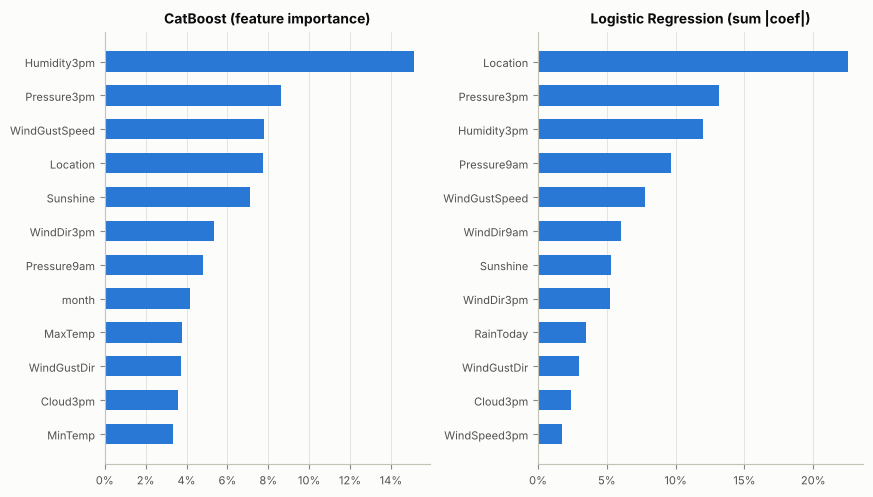

In [18]:
def aggregate_by_column(names, values):
    # Map one-hot / encoded feature names back to the original column and sum importances.
    cols = dl.NUM_COLS + dl.CAT_COLS
    out = {}
    for n, v in zip(names, values):
        base = next((c for c in sorted(cols, key=len, reverse=True) if n == c or n.startswith(c + "_")), n)
        out[base] = out.get(base, 0) + abs(v)
    return pd.Series(out)

imps = {}
cb = FITTED["CatBoost"].named_steps["model"]
if "prep" in FITTED["CatBoost"].named_steps:
    cb_names = FITTED["CatBoost"].named_steps["prep"].named_steps["columns"].get_feature_names_out()
    imps["CatBoost (feature importance)"] = aggregate_by_column(cb_names, cb.get_feature_importance())
else:
    imps["CatBoost (feature importance)"] = pd.Series(cb.feature_importances_, index=cb.feature_names_)
lr_pipe = FITTED["LR"]
if lr_pipe.named_steps["prep"].named_steps["reduce"] == "passthrough":
    lr_names = lr_pipe.named_steps["prep"].named_steps["columns"].get_feature_names_out()
    imps["Logistic Regression (sum |coef|)"] = aggregate_by_column(lr_names, lr_pipe.named_steps["model"].coef_[0])
plot_importances(imps, top=12, path=f"{FIG}/final_importances_traditional.png"); plt.show()

### 7.1 Saving extracted feature representations
The fitted preprocessing pipelines are applied to train / validation / test and the resulting matrices are stored as **gzip-compressed HDF5** (`.h5`, with labels and feature names)
and, for the compact PCA representation, also as **`.npy`**.

In [19]:
splits = {"train": (X_train, y_train), "val": (X_val, y_val), "test": (X_test, y_test)}
saved = []
for fam, fname in [("LR", "lr_features.h5"), ("RBF-SVM", "svm_features.h5"), ("CatBoost", "catboost_features.h5")]:
    steps = FITTED[fam].named_steps
    if "prep" in steps:
        saved.append(save_features(f"{FEAT}/{fname}", steps["prep"], splits,
                                   {"config": TUNED[fam]["name"], "scaler": TUNED[fam].get("scaler"),
                                    "pca": TUNED[fam].get("pca")}))
    else:
        print(f"{fam}: native categorical model -> no engineered feature matrix to save")
saved += save_npy(FEAT, "svm_pca", FITTED["RBF-SVM"].named_steps["prep"], splits)
for p in sorted(os.listdir(FEAT)):
    print(f"{p:<34} {os.path.getsize(os.path.join(FEAT, p))/1e6:7.2f} MB")

CatBoost: native categorical model -> no engineered feature matrix to save


lr_features.h5                        5.77 MB
svm_features.h5                      49.06 MB
svm_pca_X_test.npy                    7.85 MB
svm_pca_X_train.npy                  36.63 MB
svm_pca_X_val.npy                     7.85 MB
svm_pca_y_test.npy                    0.02 MB
svm_pca_y_train.npy                   0.10 MB
svm_pca_y_val.npy                     0.02 MB


## 8. Deep learning pipeline — MLP with categorical embeddings
Instead of one-hot encoding, every categorical column gets its own **learned embedding table** (size `min(16, 1.6·n^0.56)`; e.g. 14-d for `Location`, 8-d for each wind direction).
The numeric features (median-imputed, quantile-transformed to a normal distribution) and all embeddings are concatenated and passed through
`Linear(256) → BatchNorm → ReLU → Dropout(0.2) → Linear(128) → BatchNorm → ReLU → Dropout(0.2) → Linear(1)`.
**No one-hot, no PCA** — the network learns its own representation end to end.
Trained with AdamW (lr 1e-3), batch 512, binary cross-entropy, early stopping on validation ROC-AUC (patience 8). Training takes about a minute on CPU.

epoch  1  train_loss=0.3739  val_loss=0.3373  val_auc=0.8719  (5.4s)


epoch  2  train_loss=0.3435  val_loss=0.3307  val_auc=0.8769  (1.8s)


epoch  3  train_loss=0.3355  val_loss=0.3258  val_auc=0.8810  (1.9s)


epoch  4  train_loss=0.3291  val_loss=0.3251  val_auc=0.8816  (2.1s)


epoch  5  train_loss=0.3249  val_loss=0.3212  val_auc=0.8853  (2.1s)


epoch  6  train_loss=0.3207  val_loss=0.3216  val_auc=0.8851  (2.1s)


... (16 outputs left out)

epoch 23  train_loss=0.2918  val_loss=0.3159  val_auc=0.8898  (1.8s)


epoch 24  train_loss=0.2901  val_loss=0.3160  val_auc=0.8905  (1.5s)


epoch 25  train_loss=0.2896  val_loss=0.3167  val_auc=0.8903  (1.5s)


epoch 26  train_loss=0.2876  val_loss=0.3172  val_auc=0.8886  (1.5s)
early stopping (best val_auc=0.8909)
parameters: 50,041 | input width: 58 | best epoch: 18 | training time: 66.1 s | device: cpu


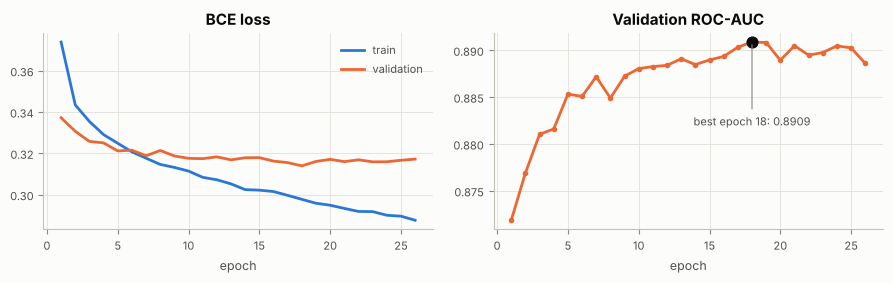

In [20]:
mlp = MLPClassifier(max_epochs=10 if FAST_MODE else 60)
Xt_nn, yt_nn = (X_train.iloc[:SUB], y_train[:SUB]) if SUB else (X_train, y_train)
mlp.fit(Xt_nn, yt_nn, X_val, y_val)
mlp_fit = mlp.train_seconds_
mlp.save(f"{FEAT}/mlp_embeddings.pt")
print(f"parameters: {mlp.n_parameters():,} | input width: {mlp.model_.d_input} | best epoch: {mlp.best_epoch_} | "
      f"training time: {mlp_fit:.1f} s | device: {mlp.device_}")
pd.DataFrame(mlp.history_).to_csv(f"{RES}/mlp_history.csv", index=False)
plot_learning_curve(mlp.history_, f"{FIG}/mlp_learning_curve.png"); plt.show()

{'train': (99535, 128), 'val': (21329, 128), 'test': (21329, 128)}


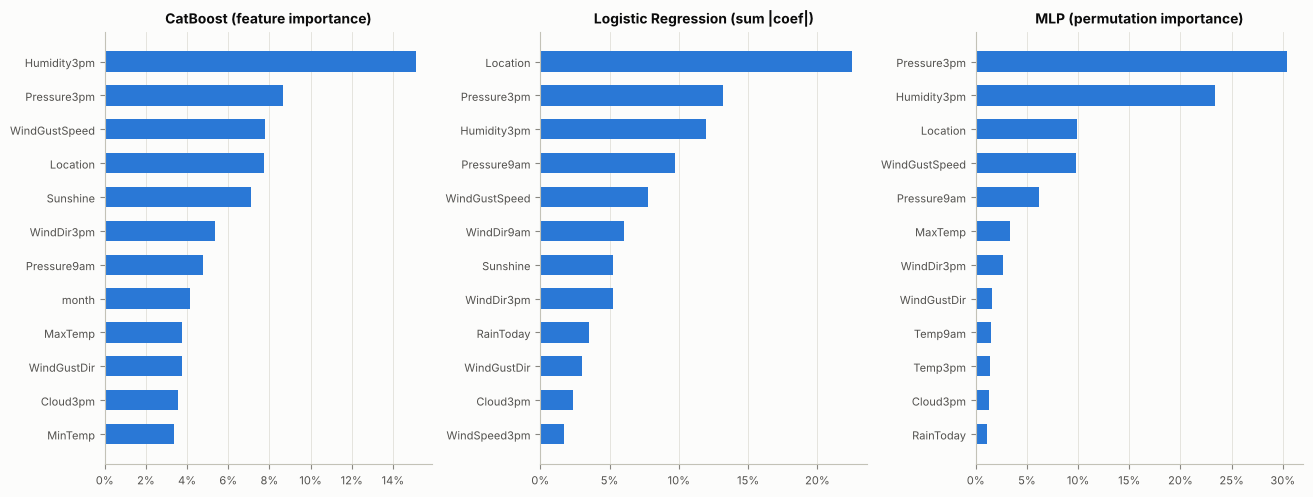

In [21]:
p_mlp = mlp.predict_proba(X_test)[:, 1]
preds["MLP"], scores["MLP"] = (p_mlp >= 0.5).astype(int), p_mlp
mlp_rec = {"name": "MLP (embeddings)", "n_features": mlp.model_.d_input,
           **compute_metrics(y_test, preds["MLP"], p_mlp), "fit_s": round(mlp_fit, 1)}

# learned 128-d hidden representation -> .h5
import h5py
hid = {name: mlp.hidden_features(X) for name, (X, y) in splits.items()}
with h5py.File(f"{FEAT}/mlp_hidden_features.h5", "w") as f:
    for name, (X, y) in splits.items():
        f.create_dataset(f"X_{name}", data=hid[name], compression="gzip")
        f.create_dataset(f"y_{name}", data=np.asarray(y, np.int8))
    f.attrs["description"] = "MLP last hidden layer (128-d) - learned representation"
print({k: v.shape for k, v in hid.items()})

# permutation importance: drop in test ROC-AUC when a column is shuffled
perm = mlp.permutation_importance(X_test, y_test)
perm.to_csv(f"{RES}/mlp_permutation_importance.csv")
plot_importances({**imps, "MLP (permutation importance)": perm}, top=12,
                 path=f"{FIG}/final_importances_all.png"); plt.show()

**Learned representation → traditional classifier.** As a check of representation quality, a plain Logistic Regression is trained on the 128-d hidden features loaded from the `.h5` file.

In [22]:
with h5py.File(f"{FEAT}/mlp_hidden_features.h5") as f:
    Etr, ytr_e, Ete = f["X_train"][:], f["y_train"][:], f["X_test"][:]
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
t0 = time.time()
lr_emb = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(Etr, ytr_e)
emb_rec = {"name": "LR on MLP hidden features", "n_features": Etr.shape[1],
           **compute_metrics(y_test, lr_emb.predict(Ete), lr_emb.predict_proba(Ete)[:, 1]),
           "fit_s": round(time.time() - t0, 1)}
emb_rec

{'name': 'LR on MLP hidden features',
 'n_features': 128,
 'accuracy': 0.8503,
 'precision': 0.7258,
 'recall': 0.594,
 'f1': 0.6534,
 'f1_macro': 0.7789,
 'roc_auc': 0.8859,
 'fit_s': 0.8}

## 9. Traditional vs. deep learning — test-set comparison

,name,n_features,accuracy,precision,recall,f1,f1_macro,roc_auc,fit_s
0,Logistic Regression,120,0.8412,0.7166,0.5485,0.6214,0.7604,0.8666,15.14
1,RBF-SVM,92,0.7853,0.5339,0.7561,0.6259,0.7376,0.8554,23.68
2,CatBoost,22,0.8556,0.7506,0.5873,0.6590,0.7837,0.8927,73.06
3,MLP (embeddings),58,0.8532,0.7340,0.5990,0.6596,0.7830,0.8874,66.10
4,LR on MLP hidden features,128,0.8503,0.7258,0.5940,0.6534,0.7789,0.8859,0.80


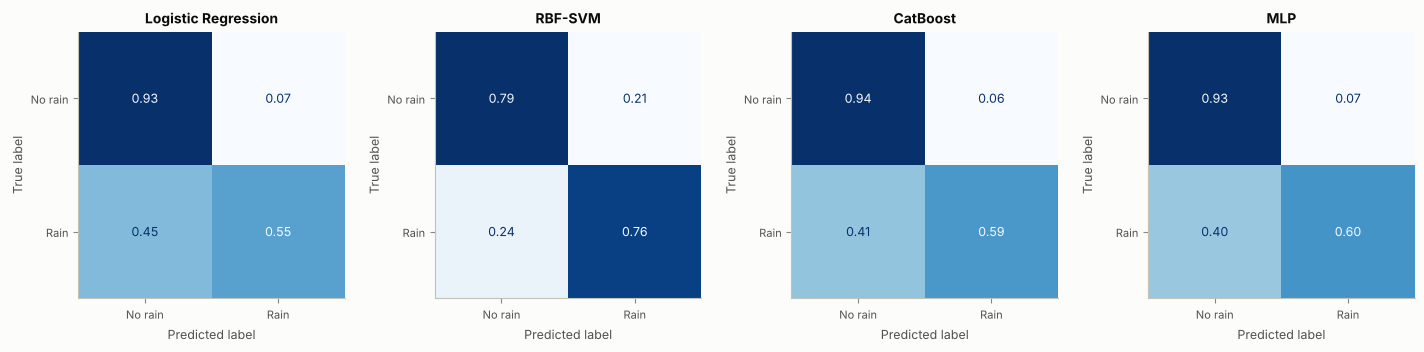

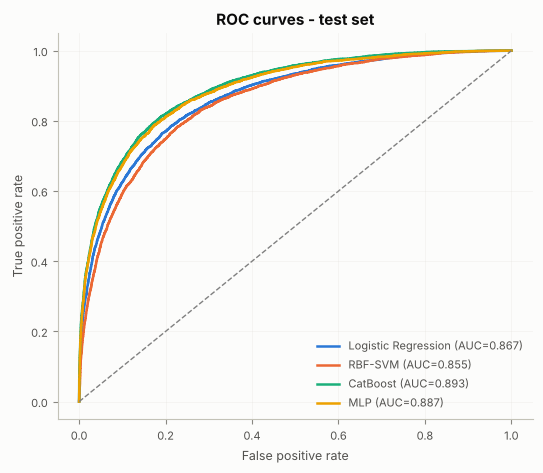

In [23]:
labels = {"LR": "Logistic Regression", "RBF-SVM": "RBF-SVM", "CatBoost": "CatBoost"}
cmp = pd.concat([final.assign(name=final.name.str.replace(" (tuned)", "", regex=False).map(labels)),
                 pd.DataFrame([mlp_rec, emb_rec])], ignore_index=True)
cmp = cmp[["name", "n_features", "accuracy", "precision", "recall", "f1", "f1_macro", "roc_auc", "fit_s"]]
cmp.to_csv(f"{RES}/final_test_comparison.csv", index=False)
display(cmp)
named = {labels.get(k, k): v for k, v in preds.items()}
plot_confusion_matrices(named, y_test, f"{FIG}/final_confusion.png"); plt.show()
plot_roc_curves({labels.get(k, k): v for k, v in scores.items()}, y_test, f"{FIG}/final_roc.png"); plt.show()

In [24]:
import json
summary = {"selected_configs": {k: {kk: (str(vv) if not isinstance(vv, (int, float, str, type(None))) else vv)
                                    for kk, vv in v.items()} for k, v in TUNED.items()},
           "mlp": {**mlp.config, "best_epoch": mlp.best_epoch_, "n_parameters": mlp.n_parameters(), "train_seconds": round(mlp_fit, 1)},
           "fast_mode": FAST_MODE, "device": str(mlp.device_)}
json.dump(summary, open(f"{RES}/summary.json", "w"), indent=2)
print(json.dumps(summary, indent=2))

{
  "selected_configs": {
    "LR": {
      "model": "lr",
      "scaler": "standard",
      "pca": null,
      "num_imputer": "iterative",
      "name": "LR (tuned)",
      "model_params": "{'C': 1.0, 'class_weight': None}"
    },
    "RBF-SVM": {
      "model": "svm",
      "scaler": "minmax",
      "feature_range": "(0, 1)",
      "pca": 0.95,
      "outliers": "quantile",
      "train_subsample": 20000,
      "name": "RBF-SVM (tuned)",
      "model_params": "{'C': 1.0, 'class_weight': 'balanced'}"
    },
    "CatBoost": {
      "name": "CatBoost (tuned)",
      "model": "catboost_native",
      "model_params": "{'depth': 8, 'iterations': 500, 'learning_rate': 0.1}"
    }
  },
  "mlp": {
    "hidden": [
      256,
      128
    ],
    "dropout": 0.2,
    "max_emb_dim": 16,
    "lr": 0.001,
    "weight_decay": 1e-05,
    "batch_size": 512,
    "max_epochs": 60,
    "patience": 8,
    "min_cat_freq": 10,
    "seed": 0,
    "best_epoch": 18,
    "n_parameters": 50041,
    "train_second

## 10. Conclusions
Full discussion: `reports/report.pdf`. Test set = the newest 15% of the days (baseline accuracy 76.2%).

| Model | Accuracy | Macro-F1 | ROC-AUC | Recall (rain) |
|---|---|---|---|---|
| Logistic Regression | 84.1% | 0.760 | 0.867 | 0.55 |
| RBF-SVM | 78.5% | 0.738 | 0.855 | 0.76 |
| **CatBoost** | **85.6%** | **0.784** | **0.893** | 0.59 |
| MLP (embeddings) | 85.3% | 0.783 | 0.887 | 0.60 |
| LR on MLP hidden features | 85.0% | 0.779 | 0.886 | 0.59 |

- **CatBoost ≈ MLP > LR > SVM.** The MLP is within 0.001 macro-F1 and 0.005 AUC of CatBoost; LR beats the SVM, which was trained on a 20k subsample, with PCA 95% and `class_weight="balanced"` (chosen on validation macro-F1), so it flags many dry days as rain (precision 0.53) and its accuracy is only 2.3 points above the baseline.
- **PCA hurt every model** and compressed only 20–23%; **iterative imputation** was the most useful preprocessing change (+0.013 LR, +0.011 SVM macro-F1); one-hot beat ordinal and target encoding (−0.010 to −0.014).
- **A random split would have inflated macro-F1 by 0.016–0.025**, so the data were split chronologically.
- The 128-d hidden features of the MLP lift a plain LR from 0.760 to 0.779 macro-F1.